# 01 · PCA — statistical factors

**Purpose.** Extract the $K$ factors that explain most of the co-movement of
$N$ asset returns. PCA is the benchmark for every other model in the package.

**Specification.** Loadings are the top-$K$ eigenvectors of the covariance
matrix $\hat\Sigma_R$ (`centered=True`, eq. 2 of Bryzgalova et al.) or of the
uncentred second moment $R'R/T$ (`centered=False`, the convention of target
PCA); `standardize=True` gives correlation PCA. Factors are **portfolios of raw
returns**, $F=R\hat\omega$, so they carry risk premia.

| Parameter | Default | Options |
|---|---|---|
| `n_factors` | 1 | number of factors $K$ |
| `centered` | `True` | covariance (`True`) or second-moment PCA (`False`) |
| `standardize` | `False` | correlation PCA, volatilities from the training sample |

**Known limitation.** PCA is consistent for *strong* factors but misses *weak*
factors that explain little variance — even if they carry large risk premia.
This notebook shows the effect; notebooks 02 and 05-07 fix it.

### How to run this notebook

```bash
pip install -e ".[notebooks]"        # package + jupyter, matplotlib, pandas
jupyter lab examples/                 # or: jupyter notebook examples/
```

All data are **synthetic with known ground truth** (generated by
`lfm.simulate_factor_returns` / `lfm.simulate_ipca_panel`), so every cell runs
offline in seconds and estimates can be compared with the truth. To use your
own data, replace the simulation cell by a `pandas.DataFrame` of excess returns
(dates x assets); every estimator accepts DataFrames directly.

In [1]:
# Setup: imports, plotting defaults and reproducibility
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import latent_factor_models as lfm

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3})
print("latent-factor-models", lfm.__version__)

latent-factor-models 0.1.0


## 1. Data with known ground truth

`simulate_factor_returns` produces three factors: a strong market-like factor,
a strong factor with a small premium and a **weak factor with a high Sharpe
ratio** (factor volatilities 4, 2, 0.6; Sharpe ratios 0.12, 0.05, 0.35).

In [2]:
sim = lfm.simulate_factor_returns(T=600, N=100, seed=0)
R = sim.returns
print(
    "R:",
    R.shape,
    "| true factor Sharpe ratios:",
    np.round(sim.factors.mean(0) / sim.factors.std(0), 3),
)

R: (600, 100) | true factor Sharpe ratios: [0.01  0.128 0.311]


## 2. How many factors?

Four estimators of $K$ work on the eigenvalue spectrum. Onatski (2010) needs an
upper bound `r_max` that must exceed the true number (a bug in the legacy code
used the current $K$ instead).

In [3]:
from latent_factor_models.selection import (
    bai_ng,
    covariance_eigenvalues,
    eigenvalue_ratio,
    giglio_xiu,
    onatski,
)

eig = covariance_eigenvalues(R)  # eigenvalues of R̄'R̄/(NT)
pd.Series(
    {
        "Onatski (2010)": onatski(eig, r_max=10),
        "Giglio-Xiu (2021)": giglio_xiu(eig, N=R.shape[1], T=R.shape[0]),
        "Bai-Ng IC2 (2002)": bai_ng(R, k_max=10),
        "Ahn-Horenstein ratio": eigenvalue_ratio(eig),
    },
    name="K",
)

Onatski (2010)          3
Giglio-Xiu (2021)       3
Bai-Ng IC2 (2002)       3
Ahn-Horenstein ratio    2
Name: K, dtype: int64

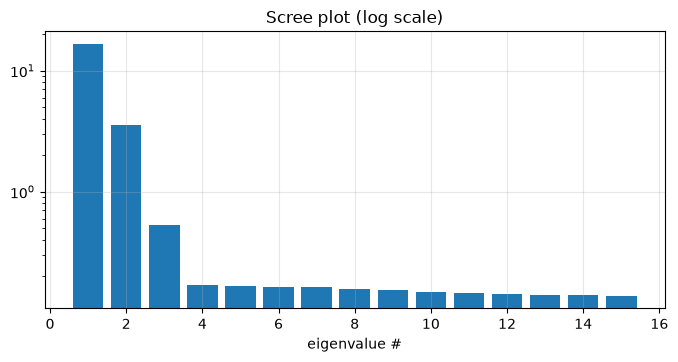

In [4]:
plt.bar(range(1, 16), eig[:15])
plt.yscale("log")
plt.title("Scree plot (log scale)")
plt.xlabel("eigenvalue #");

## 3. Estimation and outputs

In [5]:
pca = lfm.PCA(n_factors=3).fit(R)
print("absorption ratios λ_k / tr(M):", np.round(pca.absorption_ratio(), 3))
print("signal-to-noise (Lettau-Pelger):", np.round(pca.variance_signal(), 1))
pd.Series(pca.evaluate(), name="in-sample PCA")

absorption ratios λ_k / tr(M): [0.567 0.12  0.018]
signal-to-noise (Lettau-Pelger): [204.2  43.3   6.6]


sharpe_ratio             0.3210
rms_alpha                0.1311
unexplained_variation    0.3371
total_r2                 0.7060
Name: in-sample PCA, dtype: float64

## 4. Does PCA find the true factors?

The *generalised correlation* (canonical correlations between estimated and
true factors, Lettau-Pelger fn. 15) is rotation invariant: 1 means the factor
space is recovered exactly.

In [6]:
from latent_factor_models.evaluation import generalized_correlation

pd.Series(
    generalized_correlation(pca.factors_, sim.factors),
    index=["1st", "2nd", "3rd"],
    name="generalised correlation (PCA)",
)

1st    0.9970
2nd    0.9884
3rd    0.9085
Name: generalised correlation (PCA), dtype: float64

The third canonical correlation is clearly below 1: PCA only partially recovers
the **weak, highly priced** factor. Its Sharpe ratio is consequently too low.

## 5. Variants

In [7]:
variants = {
    "covariance PCA": lfm.PCA(3),
    "second-moment PCA": lfm.PCA(3, centered=False),
    "correlation PCA": lfm.PCA(3, standardize=True),
}
pd.DataFrame({k: v.fit(R).evaluate() for k, v in variants.items()}).T

,sharpe_ratio,rms_alpha,unexplained_variation,total_r2
covariance PCA,0.3210,0.1311,0.3371,0.7060
second-moment PCA,0.3311,0.1288,0.3371,0.7060
correlation PCA,0.3226,0.1303,0.3358,0.7046


## 6. Out of sample

Estimate on the first 400 months, evaluate on the remaining 200 with fixed
weights, betas and tangency portfolio.

In [8]:
m = lfm.PCA(3).fit(R[:400])
pd.DataFrame({"in-sample": m.evaluate(), "out-of-sample": m.evaluate(R[400:])})

,in-sample,out-of-sample
sharpe_ratio,0.3621,0.2202
rms_alpha,0.1601,0.2138
unexplained_variation,0.3441,0.3287
total_r2,0.6997,0.7154


**References.** Bai & Ng (2002, *Econometrica*); Onatski (2010, *REStat*);
Ahn & Horenstein (2013, *Econometrica*). Details: `docs/models/pca.md`.